In [5]:
from pathlib import Path

import numpy as np
import pandas as pd
import torch

from transformers import n_before

SEED = 42
torch.manual_seed(SEED)
np.random.seed(SEED)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'device: {torch.cuda.get_device_name()}' if device.type == 'cuda' else 'cpu')

N_PER_CLASS = None if device.type == 'cuda' else 1000

RAW_DATA_PATH = Path('data/IMDB Dataset.csv')
DATA_PATH = Path(f'data/imdb_{N_PER_CLASS or "full"}.csv')
OUTPUT_DIR = Path('output')
MODELS_DIR = Path('models')
FT_MODEL_DIR = MODELS_DIR / 'fine_tuned_model'
for d in (DATA_PATH.parent, OUTPUT_DIR, MODELS_DIR):
    d.mkdir(exist_ok=True)

device: NVIDIA GeForce RTX 4070 Laptop GPU


In [7]:
LABEL_MAP = {'negative': 0, 'positive': 1}

KAGGLE_SOURCES = [
    "vishakhdapat/imdb-movie-reviews",
    "thedevastator/imdb-large-movie-review-dataset-binary-sentiment",
]

if not DATA_PATH.exists():
    if not RAW_DATA_PATH.exists():
        import kagglehub
        for source in KAGGLE_SOURCES:
            try:
                csvs = sorted(Path(kagglehub.dataset_download(source)).glob('*.csv'),
                              key=lambda p: 'train' not in p.name.lower())
                RAW_DATA_PATH = csvs[0]
                break
            except Exception as e:
                print(f'failed to download {source}: {e}')
        else:
            raise FileNotFoundError('Dataset not found')
    print(f'Source: {RAW_DATA_PATH}')

    raw = pd.read_csv(RAW_DATA_PATH).rename(columns={'review': 'text'})

    if 'sentiment' in raw.columns:
        raw['label'] = raw['sentiment'].str.strip().str.lower().map(LABEL_MAP)
        unknown = raw['label'].isna()
        assert not unknown.any(), f"Unknown label {raw.loc[unknown, 'sentiment'].unique()}"
    raw['label'] = raw['label'].astype(int)
    assert set(raw['label'].unique()) <= {0, 1}, raw['label'].unique()

    raw['text'] = raw['text'].str.replace(r'<br\s*/?>', ' ', regex=True)
    n_before = len(raw)
    raw = raw.drop_duplicates(subset='text')
    print(f'Удалено дубликатов: {n_before - len(raw)}')

    if N_PER_CLASS is not None:
        raw = raw.groupby('label', group_keys=False).sample(n=N_PER_CLASS, random_state=SEED)
    sample = raw.sample(frac=1, random_state=SEED).reset_index(drop=True)  # перемешиваем
    sample[['text', 'label']].to_csv(DATA_PATH, index=False)

df = pd.read_csv(DATA_PATH)
print(df.shape)
print(df['label'].value_counts())
df.head()

(49582, 2)
label
1    24884
0    24698
Name: count, dtype: int64


,text,label
0,"""Soul Plane"" is a horrible attempt at comedy t...",0
1,Guest from the Future tells a fascinating stor...,1
2,"""National Treasure"" (2004) is a thoroughly mis...",0
3,"OK. First said, I just wanted to check whether...",0
4,"I haven't always been a fan, but the show grew...",1


In [8]:
from transformers import AutoTokenizer
import torch

In [9]:
model_name = "distilbert-base-uncased"


In [10]:
tokenizer = AutoTokenizer.from_pretrained(model_name)


In [11]:
print(tokenizer.vocab_size)
print(tokenizer.model_max_length)

30522
512


In [12]:
text = "This movie was absolutely amazing!"


In [13]:
tokens = tokenizer(text)
print(tokens)

{'input_ids': [101, 2023, 3185, 2001, 7078, 6429, 999, 102], 'token_type_ids': [0, 0, 0, 0, 0, 0, 0, 0], 'attention_mask': [1, 1, 1, 1, 1, 1, 1, 1]}


In [14]:
input_ids = tokens['input_ids']
print(f'Количество токенов: {len(input_ids)}')

Количество токенов: 8


In [15]:
decoded = tokenizer.decode(input_ids)
print(f'Декодировано: {decoded}')

Декодировано: [CLS] this movie was absolutely amazing! [SEP]


In [16]:
def tokenize_texts(texts, max_length=128):
    return tokenizer(
        texts,
        padding=True,
        truncation=True,
        max_length=max_length,
        return_tensors="pt"
    )

In [17]:
texts = [
    "This movie was great!",
    "Terrible movie, waste of time."
]

tokens = tokenize_texts(texts)
print(f'Shape: {tokens["input_ids"].shape}')

Shape: torch.Size([2, 9])


In [18]:
print(f'Attention mask:\n{tokens["attention_mask"]}')


Attention mask:
tensor([[1, 1, 1, 1, 1, 1, 1, 0, 0],
        [1, 1, 1, 1, 1, 1, 1, 1, 1]])


In [19]:
print(f'CLS token: {tokenizer.cls_token} (ID: {tokenizer.cls_token_id})')
print(f'SEP token: {tokenizer.sep_token} (ID: {tokenizer.sep_token_id})')
print(f'PAD token: {tokenizer.pad_token} (ID: {tokenizer.pad_token_id})')

CLS token: [CLS] (ID: 101)
SEP token: [SEP] (ID: 102)
PAD token: [PAD] (ID: 0)


In [20]:
single = tokenizer(text, return_tensors="pt")
print(f'Input IDs: {single["input_ids"]}')
print(f'Decoded: {tokenizer.decode(single["input_ids"][0])}')

Input IDs: tensor([[ 101, 2023, 3185, 2001, 7078, 6429,  999,  102]])
Decoded: [CLS] this movie was absolutely amazing! [SEP]


In [21]:
def explain_tokenization(text, tokenizer):
    tokens = tokenizer.tokenize(text)
    ids = tokenizer.convert_tokens_to_ids(tokens)

    print(f'Исходный текст: {text}')
    print(f'Токены: {tokens}')
    print(f'IDs: {ids}')
    print(f'Количество: {len(tokens)}')

explain_tokenization("Transformers are amazing!", tokenizer)

Исходный текст: Transformers are amazing!
Токены: ['transformers', 'are', 'amazing', '!']
IDs: [19081, 2024, 6429, 999]
Количество: 4


In [22]:
from transformers import AutoModel

model = AutoModel.from_pretrained(model_name)
model.to(device)
model.eval()
print(model)

Loading weights: 100%|██████████| 100/100 [00:00<00:00, 1384.71it/s]
[transformers] DistilBertModel LOAD REPORT from: distilbert-base-uncased
Key                     | Status     |  | 
------------------------+------------+--+-
vocab_projector.bias    | UNEXPECTED |  | 
vocab_transform.bias    | UNEXPECTED |  | 
vocab_layer_norm.bias   | UNEXPECTED |  | 
vocab_transform.weight  | UNEXPECTED |  | 
vocab_layer_norm.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


DistilBertModel(
  (embeddings): Embeddings(
    (word_embeddings): Embedding(30522, 768, padding_idx=0)
    (position_embeddings): Embedding(512, 768)
    (LayerNorm): LayerNorm((768,), eps=1e-12, elementwise_affine=True, bias=True)
    (dropout): Dropout(p=0.1, inplace=False)
  )
  (transformer): Transformer(
    (layer): ModuleList(
      (0-5): 6 x TransformerBlock(
        (attention): DistilBertSelfAttention(
          (q_lin): Linear(in_features=768, out_features=768, bias=True)
          (k_lin): Linear(in_features=768, out_features=768, bias=True)
          (v_lin): Linear(in_features=768, out_features=768, bias=True)
          (out_lin): Linear(in_features=768, out_features=768, bias=True)
          (dropout): Dropout(p=0.1, inplace=False)
        )
        (sa_layer_norm): LayerNorm((768,), eps=1e-12, elementwise_affine=True, bias=True)
        (ffn): FFN(
          (dropout): Dropout(p=0.1, inplace=False)
          (lin1): Linear(in_features=768, out_features=3072, bias=Tru

In [23]:
text = "This movie was absolutely amazing!"
tokens = tokenizer(text, return_tensors="pt").to(device)

with torch.no_grad():
    outputs = model(**tokens)

print(type(outputs))
print(outputs.last_hidden_state.shape)

<class 'transformers.modeling_outputs.BaseModelOutput'>
torch.Size([1, 8, 768])


In [24]:
cls_embedding = outputs.last_hidden_state[:, 0, :]
print(f'CLS embedding shape: {cls_embedding.shape}')
print(f'CLS embedding: {cls_embedding[0][:5]}...')

CLS embedding shape: torch.Size([1, 768])
CLS embedding: tensor([ 0.0682, -0.0685,  0.1918,  0.0139, -0.0544], device='cuda:0')...


In [25]:
def get_embeddings(texts, tokenizer, model, batch_size=32):
    all_embeddings = []

    for i in range(0, len(texts), batch_size):
        batch_texts = texts[i:i+batch_size]

        tokens = tokenizer(
            batch_texts,
            padding=True,
            truncation=True,
            max_length=128,
            return_tensors="pt"
        ).to(model.device)

        with torch.no_grad():
            outputs = model(**tokens)

        cls_embeddings = outputs.last_hidden_state[:, 0, :]
        all_embeddings.append(cls_embeddings.cpu().numpy())

    return np.vstack(all_embeddings)

In [26]:
texts = [
    "This movie was absolutely amazing!",
    "Terrible movie, waste of time.",
    "Pretty good, I liked it.",
    "Boring and too long."
]

embeddings = get_embeddings(texts, tokenizer, model)
print(f'Embeddings shape: {embeddings.shape}')
print(f'Ожидается: (4, 768) для DistilBERT')

Embeddings shape: (4, 768)
Ожидается: (4, 768) для DistilBERT


In [27]:
from sklearn.metrics.pairwise import cosine_similarity

def similarity(text1, text2, tokenizer, model):
    emb = get_embeddings([text1, text2], tokenizer, model)
    sim = cosine_similarity(emb[0:1], emb[1:2])[0][0]
    return sim

sim1 = similarity("Great movie!", "Amazing film!", tokenizer, model)
sim2 = similarity("Great movie!", "Terrible film!", tokenizer, model)

print(f'Сходство похожих: {sim1:.3f}')
print(f'Сходство разных: {sim2:.3f}')

Сходство похожих: 0.995
Сходство разных: 0.984


In [28]:
model_attn = AutoModel.from_pretrained(
    model_name,
    output_attentions=True,
    attn_implementation="eager",
)
model_attn.eval()

text = "The amazing movie won many awards"
tokens = tokenizer(text, return_tensors="pt")

with torch.no_grad():
    outputs = model_attn(**tokens)

print(type(outputs.attentions))
print(f'Количество слоёв: {len(outputs.attentions)}')
print(f'Форма attention для слоя 0: {outputs.attentions[0].shape}')

attention = outputs.attentions[0]
print(f'Attention shape: {attention.shape}')

attn_single = attention[0, 0]
print(f'Single head shape: {attn_single.shape}')

Loading weights: 100%|██████████| 100/100 [00:00<00:00, 1983.42it/s]
[transformers] DistilBertModel LOAD REPORT from: distilbert-base-uncased
Key                     | Status     |  | 
------------------------+------------+--+-
vocab_projector.bias    | UNEXPECTED |  | 
vocab_transform.bias    | UNEXPECTED |  | 
vocab_layer_norm.bias   | UNEXPECTED |  | 
vocab_transform.weight  | UNEXPECTED |  | 
vocab_layer_norm.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


<class 'tuple'>
Количество слоёв: 6
Форма attention для слоя 0: torch.Size([1, 12, 8, 8])
Attention shape: torch.Size([1, 12, 8, 8])
Single head shape: torch.Size([8, 8])


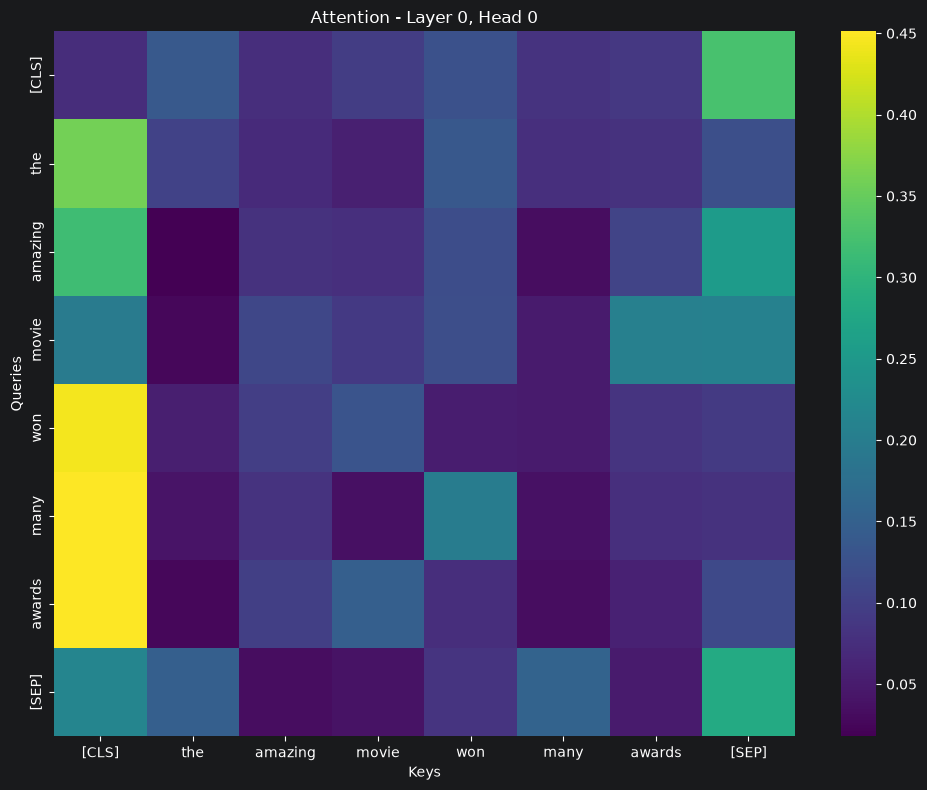

In [29]:
import matplotlib.pyplot as plt
import seaborn as sns

def visualize_attention(tokens, attention, layer=0, head=0, save=True, ax=None):

    attn = attention[layer][0, head]
    token_list = tokenizer.convert_ids_to_tokens(tokens['input_ids'][0])

    standalone = ax is None
    if standalone:
        plt.figure(figsize=(10, 8))
        ax = plt.gca()
    sns.heatmap(
        attn.cpu().numpy(),
        xticklabels=token_list,
        yticklabels=token_list,
        cmap='viridis',
        cbar=standalone,
        ax=ax,
    )
    ax.set_title(f'Attention - Layer {layer}, Head {head}')
    ax.set_xlabel('Keys')
    ax.set_ylabel('Queries')
    if standalone:
        plt.tight_layout()
        if save:
            plt.savefig(OUTPUT_DIR / f'attention_layer{layer}_head{head}.png')
        plt.show()

visualize_attention(tokens, outputs.attentions, layer=0, head=0)

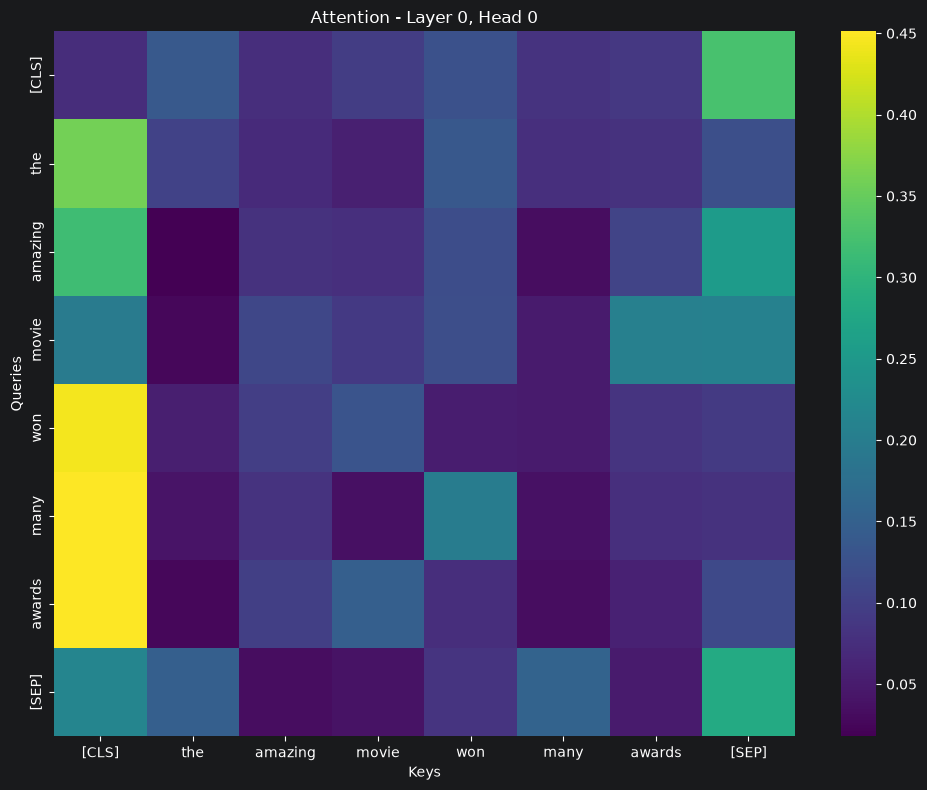

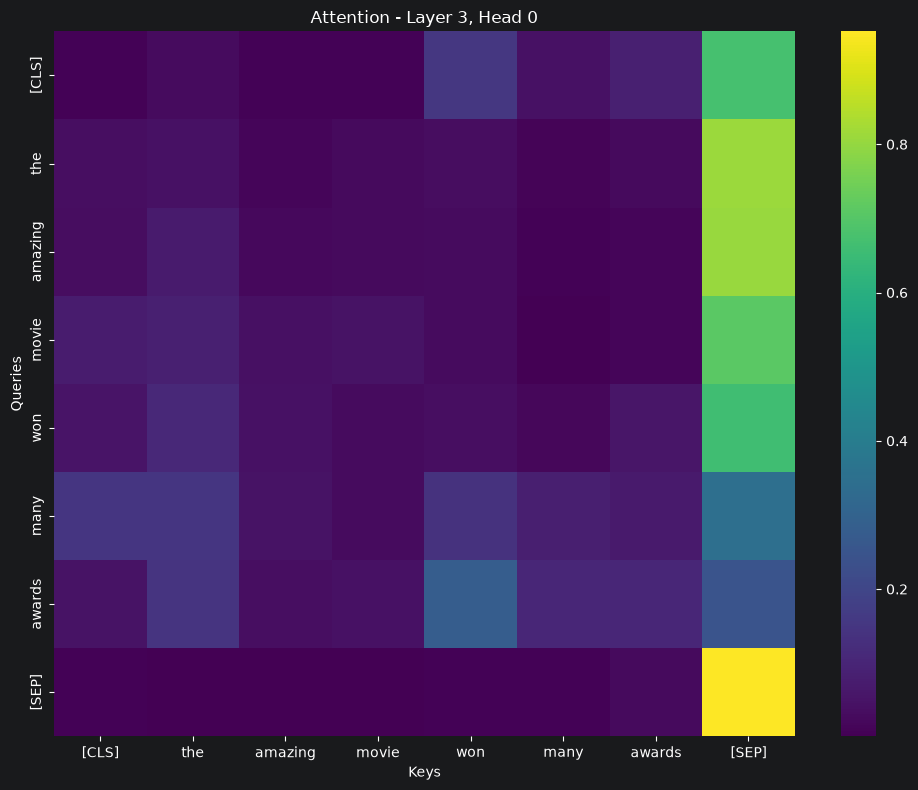

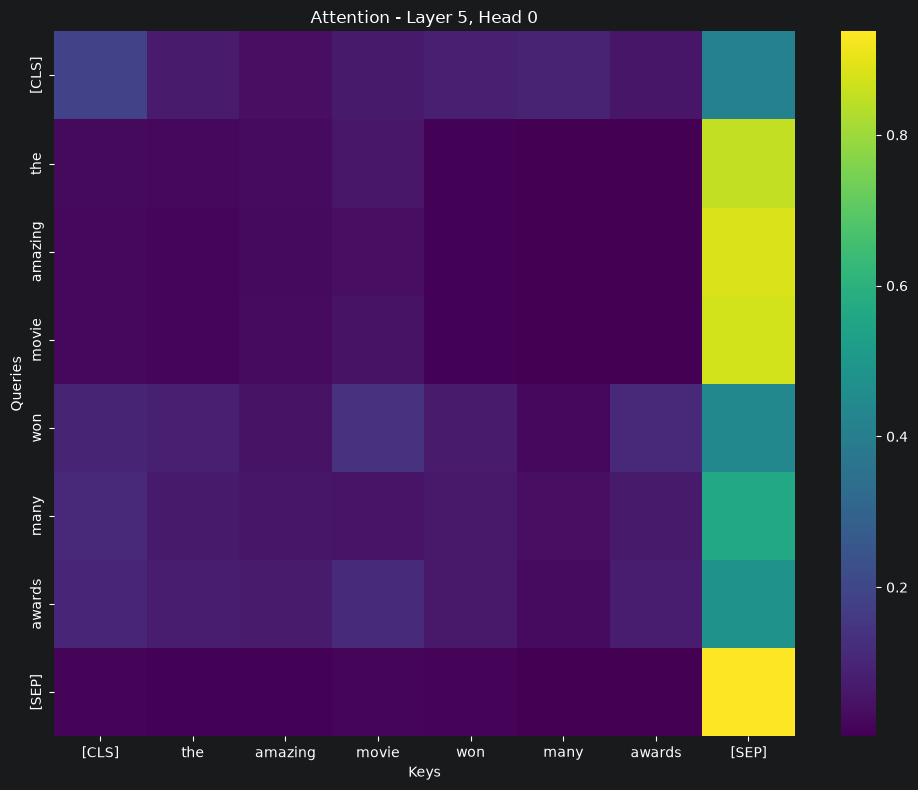

In [30]:
n_layers = model_attn.config.n_layers
for layer in (0, n_layers // 2, n_layers - 1):
    visualize_attention(tokens, outputs.attentions, layer=layer, head=0)

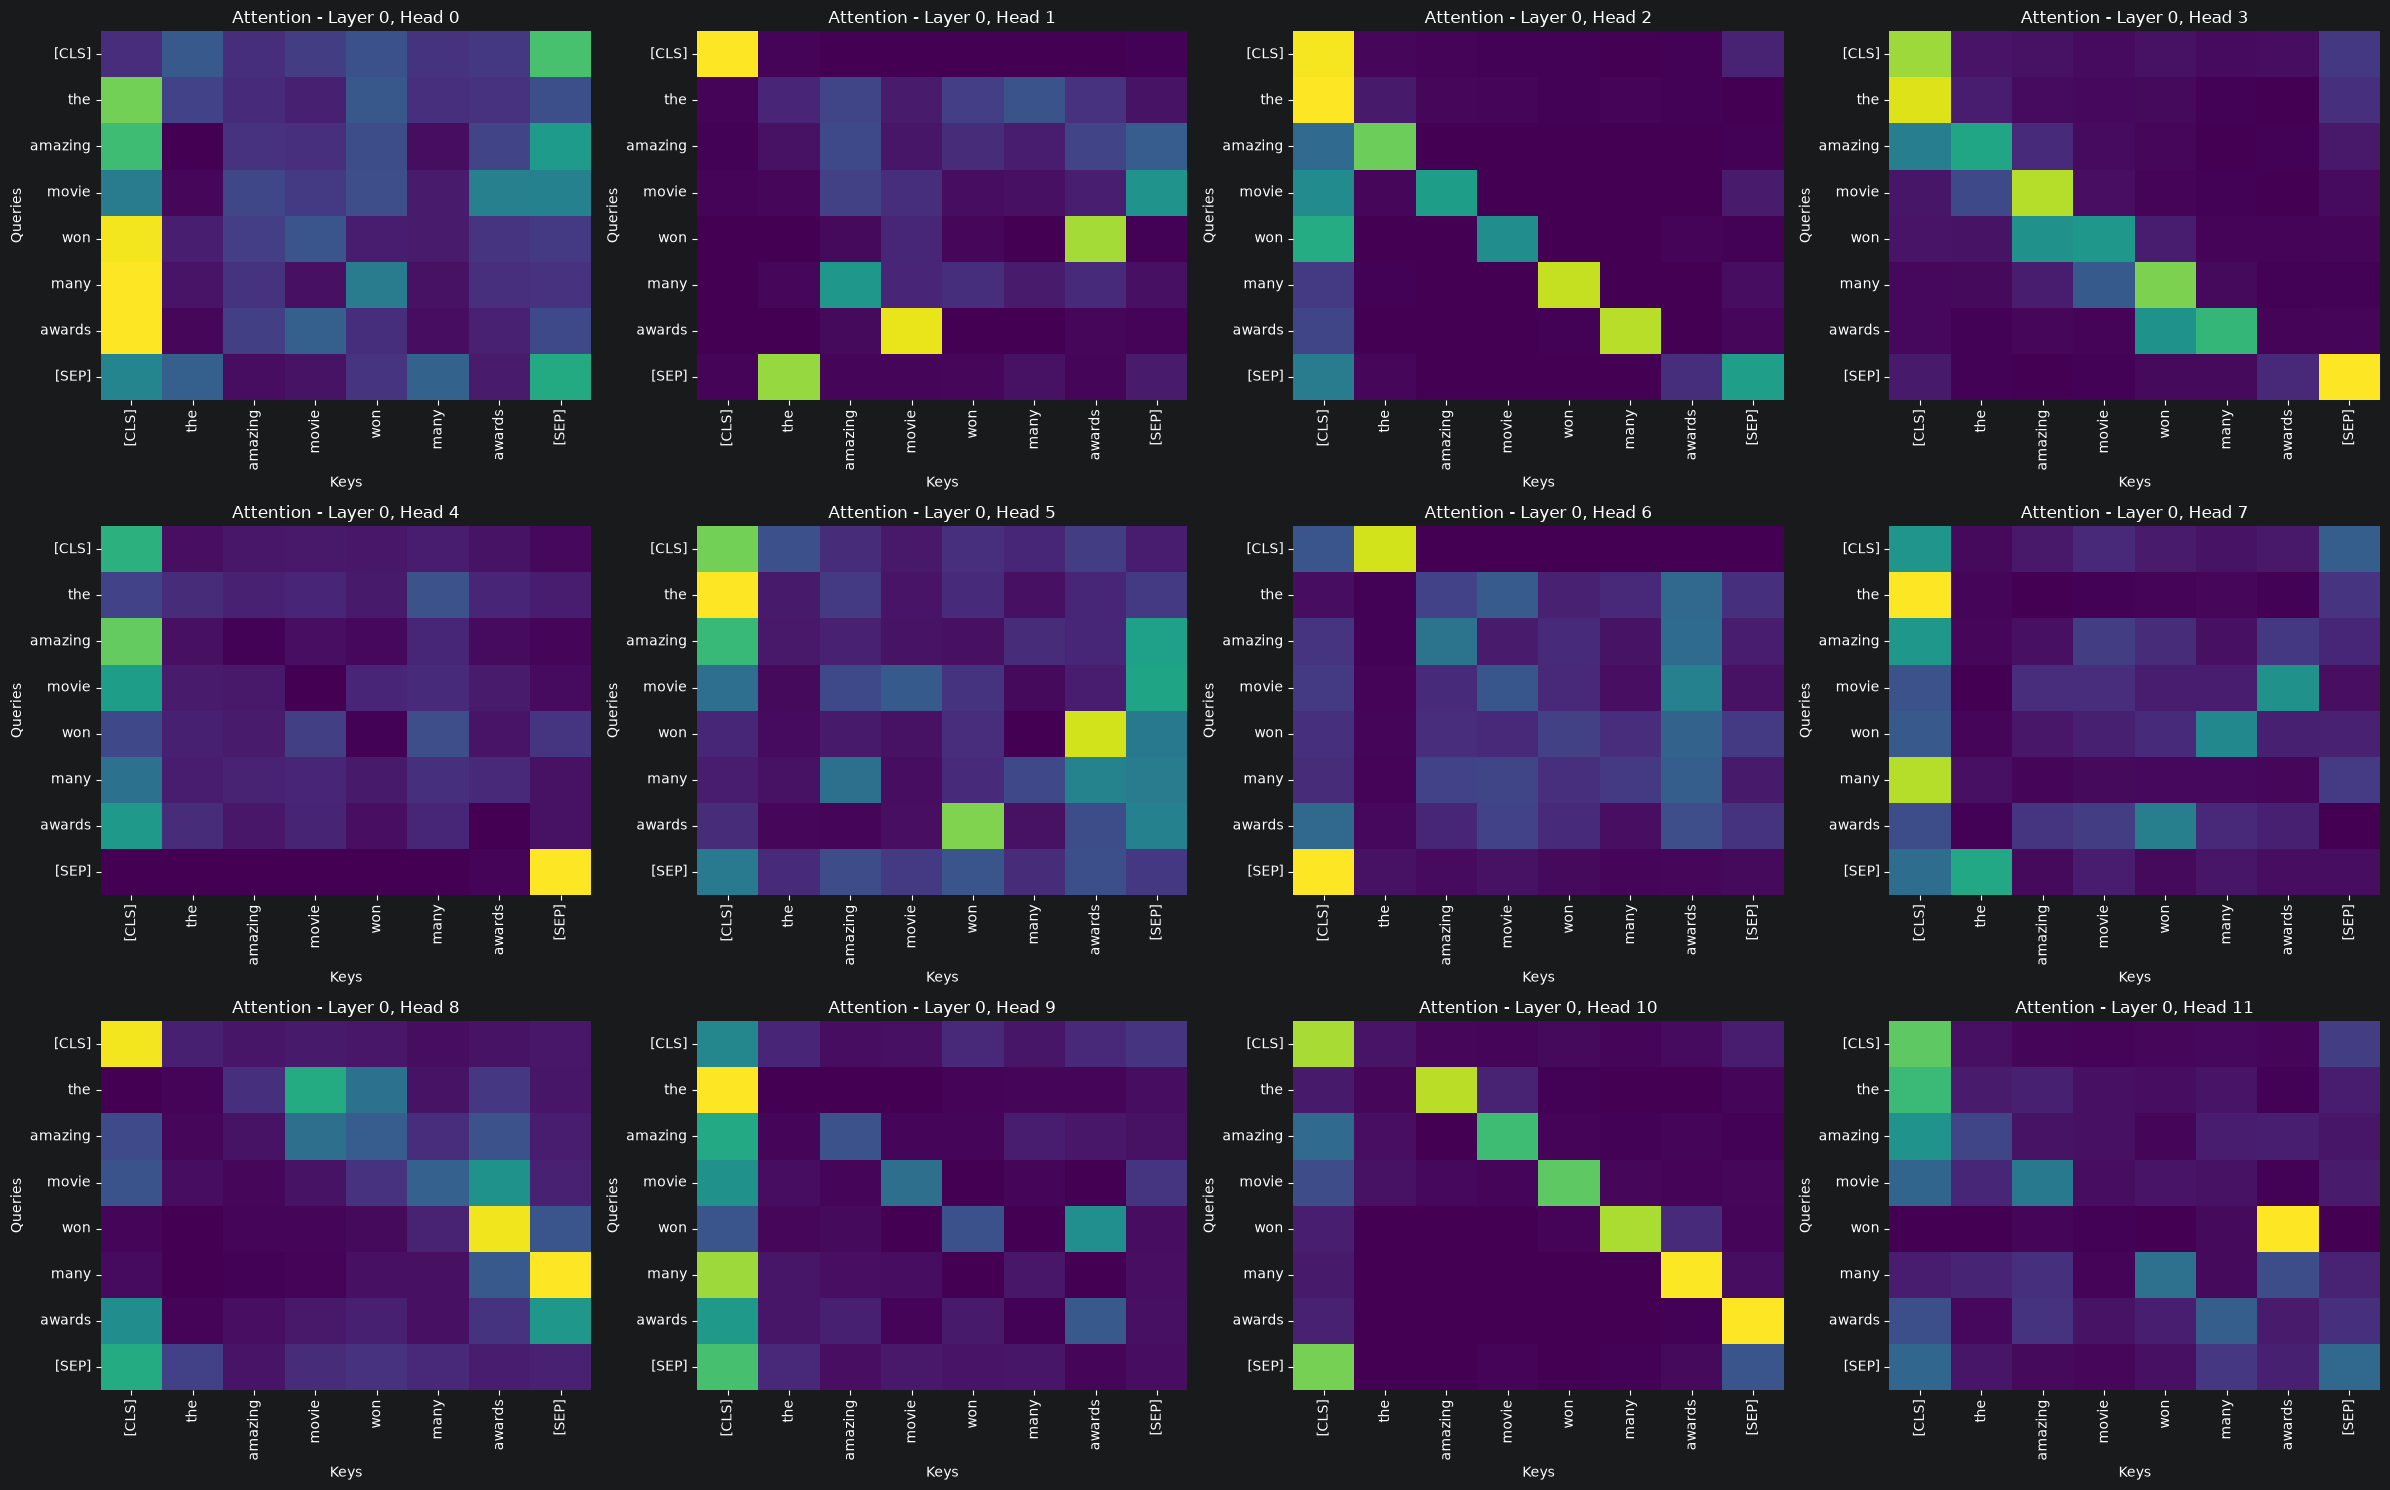

In [31]:
n_heads = model_attn.config.n_heads
fig, axes = plt.subplots(3, n_heads // 3, figsize=(24, 15))
for head, ax in enumerate(axes.flat):
    visualize_attention(tokens, outputs.attentions, layer=0, head=head, ax=ax)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'attention_layer0_all_heads.png')
plt.show()

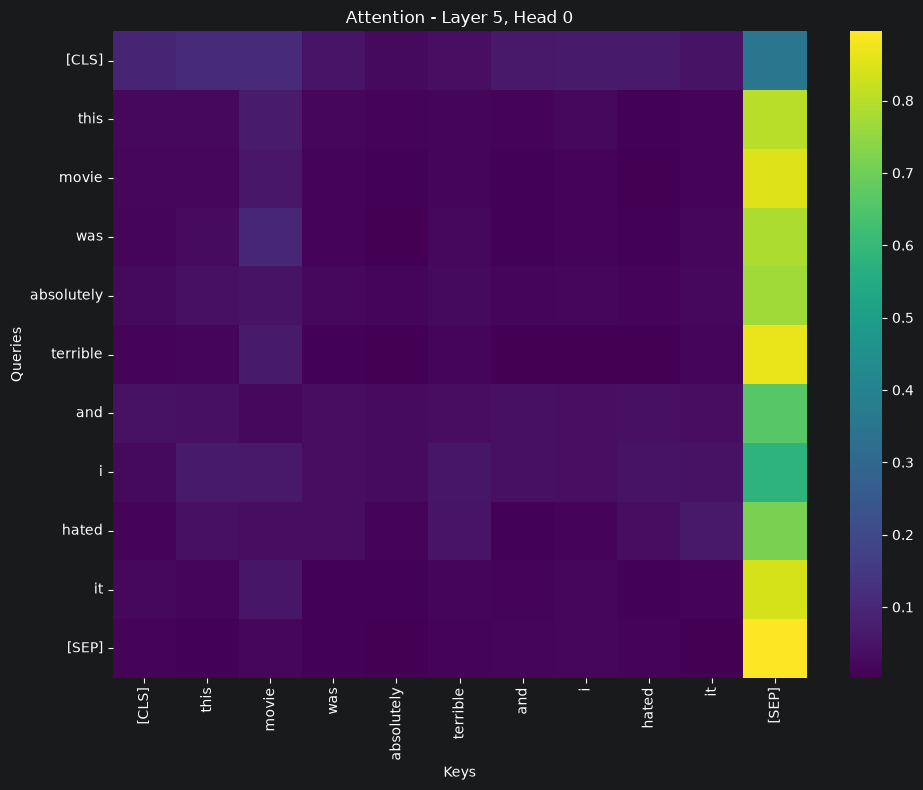

     [SEP]: 0.651
  terrible: 0.069
      this: 0.044
     movie: 0.041
       was: 0.037


In [32]:
text = "This movie was absolutely terrible and I hated it"
tokens = tokenizer(text, return_tensors="pt")

with torch.no_grad():
    outputs = model_attn(**tokens)

visualize_attention(tokens, outputs.attentions, layer=n_layers - 1, head=0)

token_list = tokenizer.convert_ids_to_tokens(tokens['input_ids'][0])
q = token_list.index('terrible')
attn_terrible = outputs.attentions[-1][0, :, q, :].mean(dim=0)
for tok, w in sorted(zip(token_list, attn_terrible.tolist()), key=lambda x: -x[1])[:5]:
    print(f'{tok:>10}: {w:.3f}')

In [33]:
def get_cls_embeddings(texts, batch_size=128):
    all_embeddings = []
    for i in range(0, len(texts), batch_size):
        batch = tokenize_texts(texts[i:i + batch_size]).to(device)
        with torch.no_grad():
            outputs = model(**batch)
        all_embeddings.append(outputs.last_hidden_state[:, 0, :].cpu().numpy())
    return np.vstack(all_embeddings)

sample_texts = ["I loved it!", "Worst film ever.", "Not bad at all."]
print(tokenize_texts(sample_texts)['input_ids'])
print(get_cls_embeddings(sample_texts).shape)

tensor([[ 101, 1045, 3866, 2009,  999,  102,    0],
        [ 101, 5409, 2143, 2412, 1012,  102,    0],
        [ 101, 2025, 2919, 2012, 2035, 1012,  102]])
(3, 768)


In [34]:
from sklearn.model_selection import train_test_split

texts = df['text'].tolist()
y = df['label'].to_numpy()

X = get_cls_embeddings(texts)
print(X.shape)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=SEED
)

(49582, 768)


In [35]:
import joblib
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, f1_score

clf = LogisticRegression(max_iter=1000)
clf.fit(X_train, y_train)
y_pred = clf.predict(X_test)

print(classification_report(y_test, y_pred))
f1 = f1_score(y_test, y_pred, average='macro')
print(f'Macro F1: {f1:.4f}')

with open(OUTPUT_DIR / 'baseline_results.txt', 'w', encoding='utf-8') as f:
    f.write(f'Baseline: DistilBERT CLS embeddings + LogisticRegression\n')
    f.write(f'Macro F1: {f1:.4f}\n')

joblib.dump(clf, MODELS_DIR / 'baseline_model.pkl')

              precision    recall  f1-score   support

           0       0.82      0.84      0.83      4940
           1       0.84      0.81      0.83      4977

    accuracy                           0.83      9917
   macro avg       0.83      0.83      0.83      9917
weighted avg       0.83      0.83      0.83      9917

Macro F1: 0.8271


['models\\baseline_model.pkl']

In [36]:
from torch.utils.data import Dataset

class SentimentDataset(Dataset):
    def __init__(self, texts, labels, tokenizer, max_length=128):
        self.texts = texts
        self.labels = labels
        self.tokenizer = tokenizer
        self.max_length = max_length

    def __len__(self):
        return len(self.texts)

    def __getitem__(self, idx):
        text = self.texts[idx]
        label = self.labels[idx]

        encoding = self.tokenizer(
            text,
            padding='max_length',
            truncation=True,
            max_length=self.max_length,
            return_tensors="pt"
        )

        return {
            'input_ids': encoding['input_ids'].flatten(),
            'attention_mask': encoding['attention_mask'].flatten(),
            'labels': torch.tensor(label, dtype=torch.long)
        }

In [37]:
texts = df['text'].tolist()
labels = df['label'].tolist()

train_texts, val_texts, train_labels, val_labels = train_test_split(
    texts, labels, test_size=0.2, random_state=SEED, stratify=labels
)

train_dataset = SentimentDataset(train_texts, train_labels, tokenizer)
val_dataset = SentimentDataset(val_texts, val_labels, tokenizer)
print(len(train_dataset), len(val_dataset))

39665 9917


In [38]:
from transformers import AutoModelForSequenceClassification
from torch.utils.data import DataLoader

num_labels = len(set(labels))
id2label = {0: 'Negative', 1: 'Positive'} if num_labels == 2 else {0: 'Negative', 1: 'Neutral', 2: 'Positive'}

model_clf = AutoModelForSequenceClassification.from_pretrained(
    model_name,
    num_labels=num_labels,
    id2label=id2label,
    label2id={v: k for k, v in id2label.items()},  # сохранятся в config → пригодятся в демо
)

train_loader = DataLoader(train_dataset, batch_size=16, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=16)

Loading weights: 100%|██████████| 100/100 [00:00<00:00, 23427.94it/s]
[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_projector.bias    | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
classifier.weight       | MISSING    | 
pre_classifier.bias     | MISSING    | 
pre_classifier.weight   | MISSING    | 
classifier.bias         | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


In [39]:
from torch.optim import AdamW
from sklearn.metrics import accuracy_score, f1_score

optimizer = AdamW(model_clf.parameters(), lr=2e-5)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
model_clf.to(device)
print(device)

cuda


In [40]:
from tqdm.auto import tqdm


def autocast(device):
    return torch.autocast(device_type=device.type, dtype=torch.bfloat16, enabled=device.type == 'cuda')


def train_epoch(model, dataloader, optimizer, device):
    model.train()
    total_loss = 0

    for batch in tqdm(dataloader, desc='train', leave=False):
        optimizer.zero_grad()

        input_ids = batch['input_ids'].to(device)
        attention_mask = batch['attention_mask'].to(device)
        labels = batch['labels'].to(device)

        with autocast(device):
            outputs = model(
                input_ids=input_ids,
                attention_mask=attention_mask,
                labels=labels
            )

        loss = outputs.loss
        loss.backward()
        optimizer.step()

        total_loss += loss.item()

    return total_loss / len(dataloader)


def evaluate(model, dataloader, device):
    model.eval()
    predictions = []
    true_labels = []

    with torch.no_grad():
        for batch in dataloader:
            input_ids = batch['input_ids'].to(device)
            attention_mask = batch['attention_mask'].to(device)
            labels = batch['labels'].to(device)

            with autocast(device):
                outputs = model(
                    input_ids=input_ids,
                    attention_mask=attention_mask
                )

            preds = torch.argmax(outputs.logits, dim=1)
            predictions.extend(preds.cpu().numpy())
            true_labels.extend(labels.cpu().numpy())

    accuracy = accuracy_score(true_labels, predictions)
    f1 = f1_score(true_labels, predictions, average='macro')

    return accuracy, f1

In [41]:
import time

num_epochs = 3

for epoch in range(num_epochs):
    start = time.time()
    train_loss = train_epoch(model_clf, train_loader, optimizer, device)
    val_acc, val_f1 = evaluate(model_clf, val_loader, device)

    print(f'Epoch {epoch+1}/{num_epochs} ({time.time() - start:.0f}s)')
    print(f'Train Loss: {train_loss:.4f}')
    print(f'Val Accuracy: {val_acc:.4f}')
    print(f'Val F1: {val_f1:.4f}')
    print('-' * 50)

Epoch 1/3 (169s)
Train Loss: 0.3263
Val Accuracy: 0.8704
Val F1: 0.8700
--------------------------------------------------


Epoch 2/3 (165s)
Train Loss: 0.2055
Val Accuracy: 0.8862
Val F1: 0.8860
--------------------------------------------------


Epoch 3/3 (164s)
Train Loss: 0.1132
Val Accuracy: 0.8886
Val F1: 0.8885
--------------------------------------------------


In [42]:
model_clf.save_pretrained(FT_MODEL_DIR)
tokenizer.save_pretrained(FT_MODEL_DIR)

with open(OUTPUT_DIR / 'fine_tuned_results.txt', 'w', encoding='utf-8') as f:
    f.write(f'Final Validation F1: {val_f1:.4f}\n')
    f.write(f'Final Validation Accuracy: {val_acc:.4f}\n')

Writing model shards: 100%|██████████| 1/1 [00:00<00:00,  3.85it/s]


In [43]:
from transformers import AutoModelForSequenceClassification, AutoTokenizer
import joblib

model_ft = AutoModelForSequenceClassification.from_pretrained(FT_MODEL_DIR)
tokenizer = AutoTokenizer.from_pretrained(FT_MODEL_DIR)
model_ft.to(device)
model_ft.eval()


class CLSVectorizer:
    def __init__(self, tokenizer, encoder):
        self.tokenizer = tokenizer
        self.encoder = encoder

    def transform(self, texts):
        return get_embeddings(texts, self.tokenizer, self.encoder)


try:
    baseline_model = joblib.load(MODELS_DIR / 'baseline_model.pkl')
    baseline_vectorizer = CLSVectorizer(tokenizer, model)
except FileNotFoundError:
    baseline_model = baseline_vectorizer = None

Loading weights: 100%|██████████| 104/104 [00:00<00:00, 1084.40it/s]


In [44]:
def predict_fine_tuned(texts, model, tokenizer, batch_size=64):
    if isinstance(texts, str):
        texts = [texts]

    predictions = []

    for i in range(0, len(texts), batch_size):
        batch_texts = texts[i:i + batch_size]
        inputs = tokenizer(batch_texts, return_tensors="pt", truncation=True, max_length=128,
                           padding=True).to(model.device)

        with torch.no_grad():
            outputs = model(**inputs)

        probs = torch.nn.functional.softmax(outputs.logits.float(), dim=1).cpu().numpy()
        for text, p in zip(batch_texts, probs):
            predictions.append({
                'text': text,
                'prediction': int(p.argmax()),
                'probabilities': p
            })

    return predictions


def predict_baseline(texts, model, vectorizer, clean_func=None):
    if isinstance(texts, str):
        texts = [texts]

    if clean_func:
        texts = [clean_func(t) for t in texts]

    X = vectorizer.transform(texts)
    predictions = model.predict(X)
    probs = model.predict_proba(X) if hasattr(model, 'predict_proba') else None

    results = []
    for i, text in enumerate(texts):
        results.append({
            'text': text,
            'prediction': int(predictions[i]),
            'probabilities': probs[i] if probs is not None else None
        })

    return results

In [45]:
example_texts = [
    "This movie was absolutely fantastic!",
    "Terrible, waste of my time.",
    "It was okay, nothing special.",
    "Best film I've seen this year!",
    "Boring and too long."
]

preds_ft = predict_fine_tuned(example_texts, model_ft, tokenizer)
if baseline_model is not None:
    preds_baseline = predict_baseline(example_texts, baseline_model, baseline_vectorizer)

for i, text in enumerate(example_texts):
    print(f'\nТекст: {text}')
    print(f'Fine-tuned: {preds_ft[i]["prediction"]} (probs: {preds_ft[i]["probabilities"]})')
    if baseline_model is not None:
        print(f'Baseline: {preds_baseline[i]["prediction"]}')
        print(f'Совпадают: {preds_ft[i]["prediction"] == preds_baseline[i]["prediction"]}')


Текст: This movie was absolutely fantastic!
Fine-tuned: 1 (probs: [0.01280237 0.9871976 ])
Baseline: 1
Совпадают: True

Текст: Terrible, waste of my time.
Fine-tuned: 0 (probs: [9.9942267e-01 5.7732774e-04])
Baseline: 0
Совпадают: True

Текст: It was okay, nothing special.
Fine-tuned: 0 (probs: [0.9128426  0.08715743])
Baseline: 1
Совпадают: False

Текст: Best film I've seen this year!
Fine-tuned: 1 (probs: [0.01151974 0.9884802 ])
Baseline: 1
Совпадают: True

Текст: Boring and too long.
Fine-tuned: 0 (probs: [0.9977133  0.00228673])
Baseline: 0
Совпадают: True


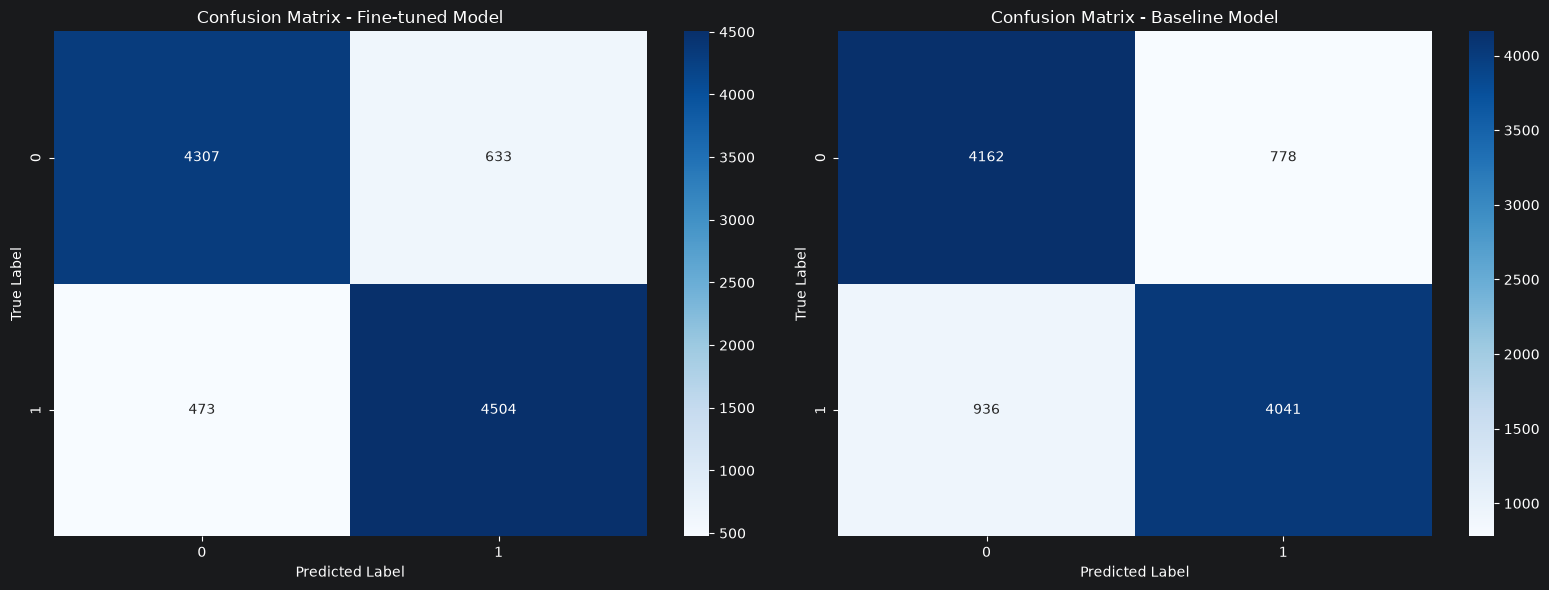

In [46]:
from sklearn.metrics import confusion_matrix

_, test_df, _, _ = train_test_split(df, df['label'], test_size=0.2, random_state=SEED, stratify=df['label'])

test_texts = test_df['text'].tolist()
test_labels = test_df['label'].tolist()

preds_ft_all = predict_fine_tuned(test_texts, model_ft, tokenizer)
y_pred_ft = [p['prediction'] for p in preds_ft_all]

cms = {'Fine-tuned': confusion_matrix(test_labels, y_pred_ft)}
if baseline_model is not None:
    preds_baseline_all = predict_baseline(test_texts, baseline_model, baseline_vectorizer)
    y_pred_base = [p['prediction'] for p in preds_baseline_all]
    cms['Baseline'] = confusion_matrix(test_labels, y_pred_base)

fig, axes = plt.subplots(1, len(cms), figsize=(8 * len(cms), 6), squeeze=False)
for ax, (name, cm) in zip(axes[0], cms.items()):
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax)
    ax.set_title(f'Confusion Matrix - {name} Model')
    ax.set_ylabel('True Label')
    ax.set_xlabel('Predicted Label')
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'confusion_matrix_finetuned.png')
plt.show()

In [47]:
from sklearn.metrics import classification_report, f1_score, accuracy_score

print("=== Fine-tuned Model ===")
print(classification_report(test_labels, y_pred_ft))
f1_ft = f1_score(test_labels, y_pred_ft, average='macro')
acc_ft = accuracy_score(test_labels, y_pred_ft)

if baseline_model is not None:
    print("\n=== Baseline Model ===")
    print(classification_report(test_labels, y_pred_base))
    f1_base = f1_score(test_labels, y_pred_base, average='macro')
    acc_base = accuracy_score(test_labels, y_pred_base)
    improvement = (f1_ft - f1_base) / f1_base * 100

    print(f'\n=== Сравнение ===')
    print(f'Fine-tuned F1: {f1_ft:.4f}, Accuracy: {acc_ft:.4f}')
    print(f'Baseline F1: {f1_base:.4f}, Accuracy: {acc_base:.4f}')
    print(f'Улучшение F1: {improvement:.2f}%')

with open(OUTPUT_DIR / 'comparison_results.txt', 'w', encoding='utf-8') as f:
    f.write('=== Сравнение моделей ===\n\n')
    f.write(f'Fine-tuned Model:\n')
    f.write(f'  F1 (macro): {f1_ft:.4f}\n')
    f.write(f'  Accuracy: {acc_ft:.4f}\n')

    if baseline_model is not None:
        f.write(f'\nBaseline Model:\n')
        f.write(f'  F1 (macro): {f1_base:.4f}\n')
        f.write(f'  Accuracy: {acc_base:.4f}\n')
        f.write(f'\nУлучшение: {improvement:.2f}%\n')

=== Fine-tuned Model ===
              precision    recall  f1-score   support

           0       0.90      0.87      0.89      4940
           1       0.88      0.90      0.89      4977

    accuracy                           0.89      9917
   macro avg       0.89      0.89      0.89      9917
weighted avg       0.89      0.89      0.89      9917


=== Baseline Model ===
              precision    recall  f1-score   support

           0       0.82      0.84      0.83      4940
           1       0.84      0.81      0.83      4977

    accuracy                           0.83      9917
   macro avg       0.83      0.83      0.83      9917
weighted avg       0.83      0.83      0.83      9917


=== Сравнение ===
Fine-tuned F1: 0.8884, Accuracy: 0.8885
Baseline F1: 0.8271, Accuracy: 0.8272
Улучшение F1: 7.41%


In [48]:
df_test = pd.DataFrame({
    'text': test_texts,
    'true_label': test_labels,
    'pred_label': y_pred_ft
})

errors = df_test[df_test['true_label'] != df_test['pred_label']].copy()

fp = errors[(errors['pred_label'] == 1) & (errors['true_label'] == 0)]
fn = errors[(errors['pred_label'] == 0) & (errors['true_label'] == 1)]

print(f'Всего ошибок: {len(errors)}')
print(f'False Positives: {len(fp)}')
print(f'False Negatives: {len(fn)}')

Всего ошибок: 1106
False Positives: 633
False Negatives: 473


In [49]:
print("=== FALSE POSITIVES (сказали good, а было bad) ===")
for idx, row in fp.head(5).iterrows():
    print(f'\nТекст: {row["text"][:100]}...')
    print(f'Истинный класс: {row["true_label"]}, Предсказан: {row["pred_label"]}')

print("\n=== FALSE NEGATIVES (сказали bad, а было good) ===")
for idx, row in fn.head(5).iterrows():
    print(f'\nТекст: {row["text"][:100]}...')
    print(f'Истинный класс: {row["true_label"]}, Предсказан: {row["pred_label"]}')

=== FALSE POSITIVES (сказали good, а было bad) ===

Текст: Devil's Experiment: 1/10: Hardcore porn films fall into two categories those with a semblance of plo...
Истинный класс: 0, Предсказан: 1

Текст: The female cast of this movie is terrific: you've got Linda Blair (maturing nicely), Julie Strain (w...
Истинный класс: 0, Предсказан: 1

Текст: Well, they say nymphomania leaves you unsatisfied. I don't know if Stella James (Sean Young) qualifi...
Истинный класс: 0, Предсказан: 1

Текст: I too am a House Party Fan...House Party I is my favorite movie of all times. House Party 4 is a dis...
Истинный класс: 0, Предсказан: 1

Текст: Earth has been destroyed in a nuclear holocaust. Well, parts of the Earth, because somewhere in Ital...
Истинный класс: 0, Предсказан: 1

=== FALSE NEGATIVES (сказали bad, а было good) ===

Текст: I think this movie would be more enjoyable if everyone thought of it as a picture of colonial Africa...
Истинный класс: 1, Предсказан: 0

Текст: This movie brings t

In [50]:
errors['text_length'] = errors['text'].str.len()
mean_err_len = errors['text_length'].mean()
mean_all_len = df_test['text'].str.len().mean()
print(f'Средняя длина ошибочных текстов: {mean_err_len:.0f}')
print(f'Средняя длина всех текстов: {mean_all_len:.0f}')

n_tokens = errors['text'].map(lambda t: len(tokenizer(t)['input_ids']))
truncated_share = (n_tokens > 128).mean()
truncated_share_all = (df_test['text'].map(lambda t: len(tokenizer(t)['input_ids'])) > 128).mean()
print(f'Обрезано до 128 токенов: ошибки {truncated_share:.0%}, все тексты {truncated_share_all:.0%}')

[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (638 > 512). Running this sequence through the model will result in indexing errors


Средняя длина ошибочных текстов: 1598
Средняя длина всех текстов: 1296
Обрезано до 128 токенов: ошибки 92%, все тексты 88%


In [51]:
with open(OUTPUT_DIR / 'error_analysis.txt', 'w', encoding='utf-8') as f:
    f.write('=== АНАЛИЗ ОШИБОК ===\n\n')
    f.write(f'Всего ошибок: {len(errors)} из {len(df_test)}\n')
    f.write(f'False Positives: {len(fp)}\n')
    f.write(f'False Negatives: {len(fn)}\n\n')

    f.write('=== ПРИМЕРЫ FALSE POSITIVES ===\n')
    for idx, row in fp.head(5).iterrows():
        f.write(f'\nТекст: {row["text"]}\n')
        f.write(f'Истинный: {row["true_label"]}, Предсказан: {row["pred_label"]}\n')

    f.write('\n\n=== ПРИМЕРЫ FALSE NEGATIVES ===\n')
    for idx, row in fn.head(5).iterrows():
        f.write(f'\nТекст: {row["text"]}\n')
        f.write(f'Истинный: {row["true_label"]}, Предсказан: {row["pred_label"]}\n')

    f.write('\n\n=== НАБЛЮДЕНИЯ ===\n')
    f.write(f'- Средняя длина ошибочных текстов: {mean_err_len:.0f} символов против {mean_all_len:.0f} в среднем.\n')
    f.write(f'- Обрезаны до 128 токенов: {truncated_share:.0%} ошибочных против {truncated_share_all:.0%} всех текстов —\n'
            f'  длинный отзыв модель видит только по началу, а итоговая оценка часто стоит в конце.\n')
    f.write('- Типичные трудные случаи: сарказм, смешанные отзывы («актёры хороши, но сюжет ужасен»),\n'
            '  пересказ сюжета с негативной лексикой при положительной оценке фильма.\n')
print(open(OUTPUT_DIR / 'error_analysis.txt', encoding='utf-8').read()[:1500])

=== АНАЛИЗ ОШИБОК ===

Всего ошибок: 1106 из 9917
False Positives: 633
False Negatives: 473

=== ПРИМЕРЫ FALSE POSITIVES ===

Текст: Devil's Experiment: 1/10: Hardcore porn films fall into two categories those with a semblance of plot (Gee that is one lucky pizza boy) and those without (Anal Amateurs 36). Devil's Experiment falls solidly into the latter category.   It is of course the horror version of hardcore porn. An almost completely plot less 43-minute wait for the money shot. Shot on video in 1985 it consists of three relatively non-descript Japanese boys torturing one fairly unattractive Japanese girl. The tortures range from the banal (slapping her 50 times, kicking her a hundred), the silly (tying her to an office chair and spinning her around), the fear factor (a bath of maggots and sheep guts) and finally the money shot. (A well executed eyeball piercing).   That's it, no plot, no motive, just Blair Witch tree shots and torture. The girl looks bored and with the exception of

In [52]:
def predict_sentiment(text):
    inputs = tokenizer(text, return_tensors="pt", truncation=True, max_length=128).to(model_ft.device)

    with torch.no_grad():
        outputs = model_ft(**inputs)

    probs = torch.nn.functional.softmax(outputs.logits, dim=1)
    pred = torch.argmax(probs, dim=1).item()
    label_map = model_ft.config.id2label

    result = f"Prediction: {label_map[pred]}\n\n"
    result += "Probabilities:\n"
    for i, prob in enumerate(probs[0]):
        result += f"{label_map[i]}: {prob*100:.2f}%\n"
    return result

print(predict_sentiment("One of the best movies I have ever seen."))
print(predict_sentiment("I want those two hours of my life back."))

Prediction: Positive

Probabilities:
Negative: 0.38%
Positive: 99.62%

Prediction: Positive

Probabilities:
Negative: 0.63%
Positive: 99.37%



In [53]:
import re

readme_path = Path('README.md')
lines = ['### Fine-tuned модель:', f'- F1 (macro): {f1_ft:.4f}', f'- Accuracy: {acc_ft:.4f}', '']
if baseline_model is not None:
    lines += ['### Baseline модель:', f'- F1 (macro): {f1_base:.4f}', f'- Accuracy: {acc_base:.4f}', '',
              f'Улучшение: {improvement:.2f}%']
block = '<!-- results:start -->\n' + '\n'.join(lines) + '\n<!-- results:end -->'

readme = readme_path.read_text(encoding='utf-8')
readme = re.sub(r'<!-- results:start -->.*?<!-- results:end -->', lambda _: block, readme, flags=re.S)
readme_path.write_text(readme, encoding='utf-8')
print(block)

<!-- results:start -->
### Fine-tuned модель:
- F1 (macro): 0.8884
- Accuracy: 0.8885

### Baseline модель:
- F1 (macro): 0.8271
- Accuracy: 0.8272

Улучшение: 7.41%
<!-- results:end -->
